## Lecture 15 Notebook - More Models

In [1]:
#Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
tips = pd.read_csv('tips.csv')
tips.head()

,total_bill,tip,smoker,day,time,size
0,16.99,1.01,No,Sun,Dinner,2
1,10.34,1.66,No,Sun,Dinner,3
2,21.01,3.50,No,Sun,Dinner,3
3,23.68,3.31,No,Sun,Dinner,2
4,24.59,3.61,No,Sun,Dinner,4


[Text(0.5, 1.0, 'Relationship between Tip and Total Bill')]

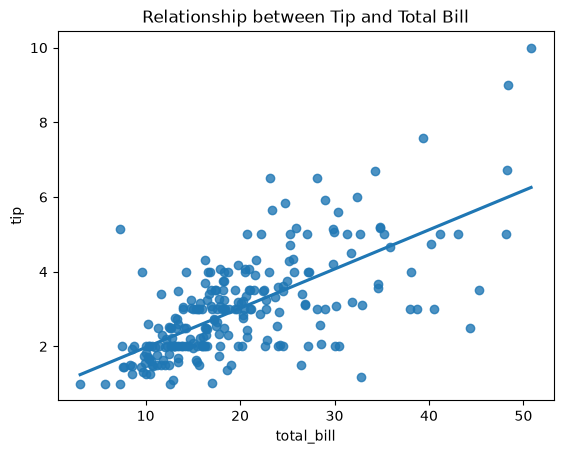

In [3]:
import seaborn as sns
sns.regplot(x='total_bill', y = 'tip', ci = None, data = tips).set(title = 'Relationship between Tip and Total Bill')

In [4]:
import statsmodels.formula.api as smf
results1 = smf.ols(formula = 'tip ~ total_bill', data = tips).fit()
results1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    tip   R-squared:                       0.457
Model:                            OLS   Adj. R-squared:                  0.454
Method:                 Least Squares   F-statistic:                     203.4
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           6.69e-34
Time:                        15:11:11   Log-Likelihood:                -350.54
No. Observations:                 244   AIC:                             705.1
Df Residuals:                     242   BIC:                             712.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.9203      0.160      5.761      0.000       0.606       1.235
total_bill     0.1050      0.007     14.260      0.000       0.091       0.120
==============================================================================
Omnibus:                       20.185   Durbin-Watson:                   2.151
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               37.750
Skew:                           0.443   Prob(JB):                     6.35e-09
Kurtosis:                       4.711   Cond. No.                         53.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [5]:
import statsmodels.formula.api as smf
results2 = smf.ols(formula = 'tip ~ total_bill + size', data = tips).fit()
results2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    tip   R-squared:                       0.468
Model:                            OLS   Adj. R-squared:                  0.463
Method:                 Least Squares   F-statistic:                     105.9
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           9.67e-34
Time:                        15:11:11   Log-Likelihood:                -347.99
No. Observations:                 244   AIC:                             702.0
Df Residuals:                     241   BIC:                             712.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.6689      0.194      3.455      0.001       0.288       1.050
total_bill     0.0927      0.009     10.172      0.000       0.075       0.111
size           0.1926      0.085      2.258      0.025       0.025       0.361
==============================================================================
Omnibus:                       24.753   Durbin-Watson:                   2.100
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               46.169
Skew:                           0.545   Prob(JB):                     9.43e-11
Kurtosis:                       4.831   Cond. No.                         67.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [6]:
results2.params

Intercept     0.668945
total_bill    0.092713
size          0.192598
dtype: float64

In [17]:
tips['mult'] = tips['total_bill'] *results2.params.iloc[1] + results2.params.iloc[0] + results2.params.iloc[2]
tips.head()

,total_bill,tip,smoker,day,time,size,mult
0,16.99,1.01,No,Sun,Dinner,2,2.436742
1,10.34,1.66,No,Sun,Dinner,3,1.820198
2,21.01,3.50,No,Sun,Dinner,3,2.809450
3,23.68,3.31,No,Sun,Dinner,2,3.056994
4,24.59,3.61,No,Sun,Dinner,4,3.141363


In [8]:
results3 = smf.ols(formula = 'tip ~ total_bill + size + smoker + day + time', data = tips).fit()
results3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    tip   R-squared:                       0.470
Model:                            OLS   Adj. R-squared:                  0.454
Method:                 Least Squares   F-statistic:                     29.89
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           2.15e-29
Time:                        15:11:11   Log-Likelihood:                -347.50
No. Observations:                 244   AIC:                             711.0
Df Residuals:                     236   BIC:                             739.0
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         0.7896      0.346      2.279      0.024       0.107       1.472
smoker[T.Yes]    -0.0865      0.146     -0.591      0.555      -0.375       0.202
day[T.Sat]       -0.1259      0.309     -0.408      0.684      -0.734       0.482
day[T.Sun]       -0.0326      0.319     -0.102      0.919      -0.661       0.596
day[T.Thur]      -0.1609      0.393     -0.410      0.682      -0.934       0.612
time[T.Lunch]     0.0681      0.444      0.154      0.878      -0.806       0.942
total_bill        0.0943      0.010      9.884      0.000       0.075       0.113
size              0.1764      0.089      1.974      0.050       0.000       0.352
==============================================================================
Omnibus:                       27.521   Durbin-Watson:                   2.099
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               51.508
Skew:                           0.603   Prob(JB):                     6.53e-12
Kurtosis:                       4.901   Cond. No.                         205.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [9]:
from mpl_toolkits.mplot3d import Axes3D

/var/folders/9r/zksxc13j5h14fzdjc6lgmt5h0000gq/T/ipykernel_18356/1272027168.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  z_plane = results2.params[1] * x_plane + results2.params[2] * y_plane + results2.params[0]


Text(0.5, 0, 'tip($)')

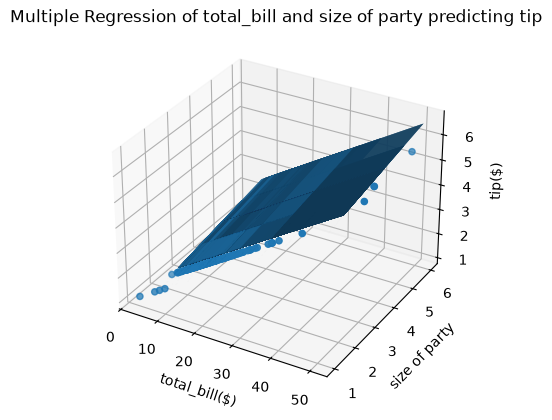

In [10]:

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

#Add data points to the 3d scatter plot:
ax.scatter(tips["total_bill"], tips["size"], tips["mult"])

#Create a meshgrid for the plane:
x_plane, y_plane = np.meshgrid(tips["total_bill"], tips["size"])
z_plane = results2.params[1] * x_plane + results2.params[2] * y_plane + results2.params[0]

#Plot the plane with selected transparency value:
ax.plot_surface(x_plane, y_plane, z_plane, alpha=0.5)

#Title and label graph:
ax.set_title('Multiple Regression of total_bill and size of party predicting tip')
ax.set_xlabel('total_bill($)')
ax.set_ylabel('size of party')
ax.set_zlabel('tip($)')


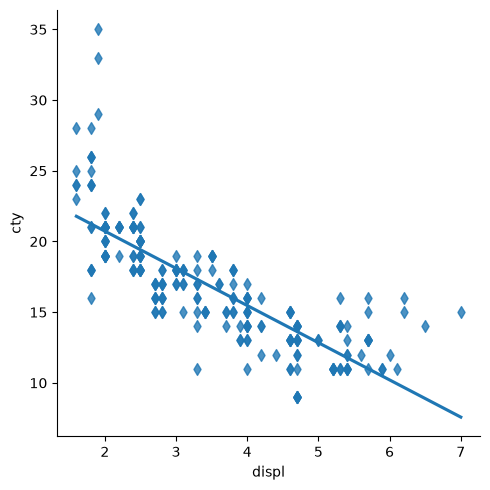

In [11]:
import seaborn as sns
mpg = pd.read_csv('mpg.csv')
sns.lmplot(data=mpg, x='displ', y = 'cty', ci=None, markers='d')

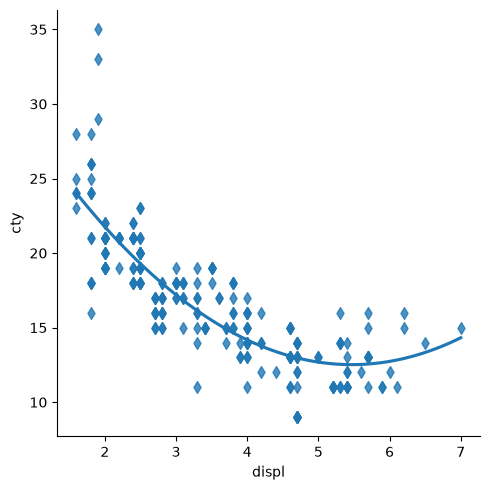

In [12]:
sns.lmplot(data=mpg, x='displ', y = 'cty', ci=None, markers='d', order= 2)

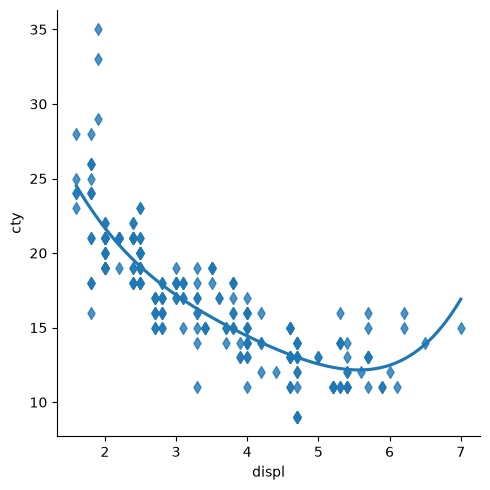

In [13]:
sns.lmplot(data=mpg, x='displ', y = 'cty', ci=None, markers='d', order= 4)

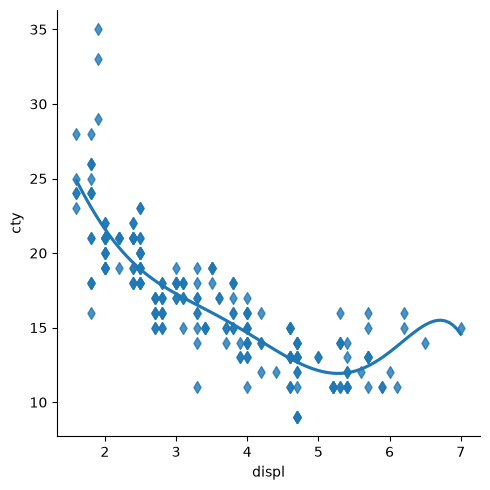

In [14]:
sns.lmplot(data=mpg, x='displ', y = 'cty', ci=None, markers='d', order= 6)

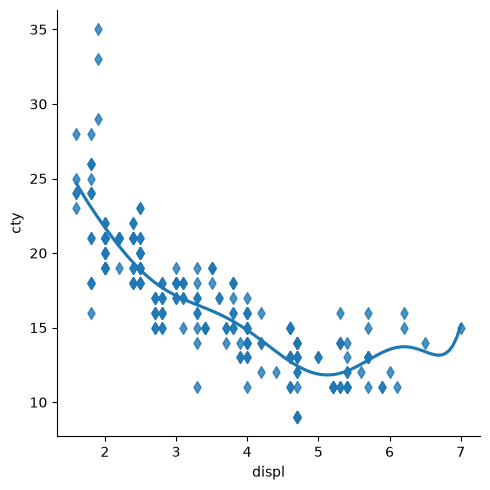

In [15]:
sns.lmplot(data=mpg, x='displ', y = 'cty', ci=None, markers='d', order= 8)

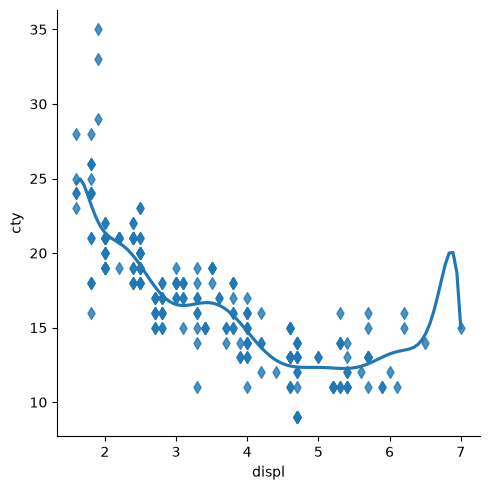

In [16]:
sns.lmplot(data=mpg, x='displ', y = 'cty', ci=None, markers='d', order= 12)

In [41]:
coefficients = np.polyfit(mpg['displ'], mpg['cty'], 2)
coefficients

array([ 0.76826417, -8.40223672, 35.49277815])

In [42]:
polynomial=np.poly1d(coefficients)
print(polynomial)

        2
0.7683 x - 8.402 x + 35.49


In [45]:
mpg['fit2']=polynomial(mpg['displ'])
mpg

,Unnamed: 0,manufacturer,model,displ,year,cyl,trans,drv,cty,hwy,fl,class,fit2
0,1,audi,a4,1.8,1999,4,auto(l5),f,18,29,p,compact,22.857928
1,2,audi,a4,1.8,1999,4,manual(m5),f,21,29,p,compact,22.857928
2,3,audi,a4,2.0,2008,4,manual(m6),f,20,31,p,compact,21.761361
3,4,audi,a4,2.0,2008,4,auto(av),f,21,30,p,compact,21.761361
4,5,audi,a4,2.8,1999,6,auto(l5),f,16,26,p,compact,17.989706
...,...,...,...,...,...,...,...,...,...,...,...,...,...
229,230,volkswagen,passat,2.0,2008,4,auto(s6),f,19,28,p,midsize,21.761361
230,231,volkswagen,passat,2.0,2008,4,manual(m6),f,21,29,p,midsize,21.761361
231,232,volkswagen,passat,2.8,1999,6,auto(l5),f,16,26,p,midsize,17.989706
232,233,volkswagen,passat,2.8,1999,6,manual(m5),f,18,26,p,midsize,17.989706


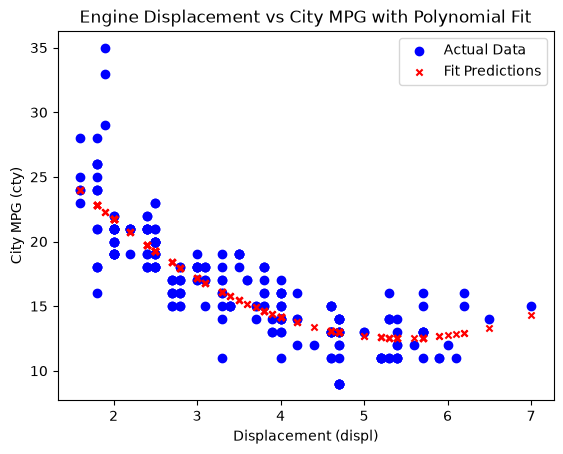

In [ ]:
fig, ax = plt.subplots()

# Actual data
plt.scatter(data=mpg, x='displ', y='cty', marker='o', label='Actual Data', color='blue')

# Fitted predictions as independent dots
mpg.plot.scatter(x='displ', y='fit2', ax=ax, label='Fit Predictions', color='red', marker='x')

plt.xlabel('Displacement (displ)')
plt.ylabel('City MPG (cty)')
plt.title('Engine Displacement vs City MPG with Polynomial Fit')
plt.legend()